# RainGuard — Module 1: Dataset Inspection & Preprocessing
**Indian Rainfall Forecasting and Heavy Rainfall Risk Analysis System**

**What this notebook does**
1. Sets up the project folders and loads the real IMD district-wise CSV.
2. Inspects shape, data types, column names, dates, missing values, duplicates and category distributions.
3. Cleans the data (column names, state spellings, dates, percentage columns).
4. Checks time-series completeness and outliers.
5. Builds the rainfall *intensity* label from IMD thresholds.
6. Encodes categorical variables, adds calendar features and saves the cleaned dataset.

**Important:** this project predicts rainfall *intensity*. It does **not** predict floods, because the dataset has no flood-occurrence records.

Run the cells from top to bottom. Place this notebook in `RainGuard/notebooks/` and the CSV in `RainGuard/data/raw/` (the notebook also finds the CSV if it sits next to it).

## Step 1 — Imports, project folders and data path
We create the folder structure the assignment asks for and locate the CSV automatically.

In [1]:
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

# Project root = parent of "notebooks" if we are inside it, else current folder
cwd = os.getcwd()
PROJECT_ROOT = os.path.abspath(os.path.join(cwd, "..")) if os.path.basename(cwd) == "notebooks" else cwd

for folder in ["data/raw", "data/processed", "notebooks", "models",
               "templates", "static", "docs", "docs/figures"]:
    os.makedirs(os.path.join(PROJECT_ROOT, folder), exist_ok=True)

FILE = "rainfall_districtwise_daily_imd.csv"
candidates = [os.path.join(PROJECT_ROOT, "data", "raw", FILE),
              os.path.join(cwd, FILE),
              os.path.join(PROJECT_ROOT, FILE)]
DATA_PATH = next((p for p in candidates if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"Put {FILE} in {os.path.join(PROJECT_ROOT, 'data', 'raw')}")

FIG_DIR = os.path.join(PROJECT_ROOT, "docs", "figures")
print("Project root:", PROJECT_ROOT)
print("Reading data from:", DATA_PATH)

Project root: C:\Users\ahmed\Downloads
Reading data from: C:\Users\ahmed\Downloads\rainfall_districtwise_daily_imd.csv


## Step 2 — Load and inspect the raw data
`raw` is kept untouched so we can always compare against the original. All cleaning happens on a copy called `df`.

**What to look for:** the column names contain hidden newline characters (`\n`) and spelling mistakes (`Departue`, `Acutual`). We fix these in Step 3.

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", raw.shape)

print("\nRaw column names (repr shows hidden characters):")
for c in raw.columns:
    print("  ", repr(c))

print()
raw.info()
display(raw.head())

Shape (rows, columns): (53102, 22)

Raw column names (repr shows hidden characters):
   'State'
   'District'
   'Date'
   'Daily Actual'
   'Daily Normal'
   'Daily Departure Per'
   'Daily Category'
   'Week Date'
   'Weekly \nActual'
   'Weekly Normal'
   'Weekly Departure Per'
   'Weekly Category'
   'Cumulative Date'
   'Cumulative Actual'
   'Cumulative Normal'
   'Cumulative Departue Per'
   'Cumulative \nCategory'
   'Monthly Date'
   'Monthly Acutual'
   'Monthly Normal'
   'Monthly \nDeparture Per'
   'Monthly Category'

<class 'pandas.DataFrame'>
RangeIndex: 53102 entries, 0 to 53101
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   State                    53102 non-null  str    
 1   District                 53102 non-null  str    
 2   Date                     53102 non-null  str    
 3   Daily Actual             53102 non-null  float64
 4   Daily Normal             53102 non-n

,State,District,Date,Daily Actual,Daily Normal,Daily Departure Per,Daily Category,Week Date,Weekly \nActual,Weekly Normal,Weekly Departure Per,Weekly Category,Cumulative Date,Cumulative Actual,Cumulative Normal,Cumulative Departue Per,Cumulative \nCategory,Monthly Date,Monthly Acutual,Monthly Normal,Monthly \nDeparture Per,Monthly Category
0,ANDAMAN & NICOBAR,NICOBAR,2026-08-19,0.5,7.4,-94%,LD,13-08-2026 To 19-08-2026,0.5,7.4,-94%,LD,2026-06-01,431.7,686.9,-37%,D,From 01-08-2026 To 19-08-2026\r,186.1,141.5,31%,E
1,ANDAMAN & NICOBAR,NICOBAR,2026-08-20,0.5,9.4,-94%,LD,13-08-2026 To 19-08-2026,17.5,45.2,-61%,LD,2026-06-01,432.3,696.3,-38%,D,From 01-08-2026 To 20-08-2026\r,186.6,150.9,24%,E
2,ANDAMAN & NICOBAR,NICOBAR,2026-08-21,2.4,9.9,-76%,LD,13-08-2026 To 19-08-2026,17.5,45.2,-61%,LD,2026-06-01,431.7,686.9,-37%,D,From 01-08-2026 To 21-08-2026\r,189.0,160.8,18%,N
3,ANDAMAN & NICOBAR,NICOBAR,2026-08-22,9.3,7.1,31%,E,13-08-2026 To 19-08-2026,17.5,45.2,-61%,LD,2026-06-01,444.0,713.3,-38%,D,From 01-08-2026 To 22-08-2026\r,198.3,167.9,18%,N
4,ANDAMAN & NICOBAR,NICOBAR,2026-08-23,1.3,7.9,-83%,LD,13-08-2026 To 19-08-2026,1.3,7.9,-83%,LD,2026-06-01,445.3,721.2,-38%,D,From 01-08-2026 To 23-08-2026\r,199.7,175.8,14%,N


## Step 3 — Standardize column names
Rules: lower-case, whitespace/newlines → single underscore, and fix two spelling mistakes in the source file.
Also, the columns ending in `_departure_per` hold text like `"-94%"`; we will rename them to `_departure_pct` once converted to numbers.

In [3]:
df = raw.copy()

def clean_col(c):
    c = re.sub(r"\s+", " ", c).strip().lower()
    return c.replace(" ", "_")

df.columns = [clean_col(c) for c in df.columns]
df = df.rename(columns={"cumulative_departue_per": "cumulative_departure_per",
                        "monthly_acutual": "monthly_actual"})
print(list(df.columns))

['state', 'district', 'date', 'daily_actual', 'daily_normal', 'daily_departure_per', 'daily_category', 'week_date', 'weekly_actual', 'weekly_normal', 'weekly_departure_per', 'weekly_category', 'cumulative_date', 'cumulative_actual', 'cumulative_normal', 'cumulative_departure_per', 'cumulative_category', 'monthly_date', 'monthly_actual', 'monthly_normal', 'monthly_departure_per', 'monthly_category']


## Step 4 — Clean text columns and unify state spellings
IMD's file spells two states in two ways:
* `CHHATISGARH` (31 districts) vs `CHHATTISGARH` (1 district)
* `TAMIL NADU` (37 districts) vs `TAMILNADU` (1 district)

If we leave this, the same state is split into two groups, which would corrupt every state-wise analysis and the state encoding. The districts in the two spellings do not overlap, so merging is safe.

In [4]:
# strip stray spaces / '\r' from every text column
for c in df.columns:
    if not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = df[c].str.strip()

df["state"] = df["state"].str.upper()
df["district"] = df["district"].str.upper()

print("States before merge:", df["state"].nunique())
state_fix = {"CHHATISGARH": "CHHATTISGARH", "TAMILNADU": "TAMIL NADU"}
df["state"] = df["state"].replace(state_fix)
print("States after merge :", df["state"].nunique())

# safety checks: each district belongs to exactly one state, count is still 728
print("Districts:", df["district"].nunique(),
      "| (state, district) pairs:", df.groupby(["state", "district"]).ngroups)
print("Districts appearing in more than one state:",
      int((df.groupby("district")["state"].nunique() > 1).sum()))

States before merge: 39
States after merge : 37
Districts: 728 | (state, district) pairs: 728
Districts appearing in more than one state: 0


## Step 5 — Convert dates to datetime
* `date` and `cumulative_date` are ISO dates and convert directly.
* `week_date` and `monthly_date` are *text windows* such as `From 01-08-2026 To 19-08-2026`. We extract the start and end dates so we can check what period each window covers.

In [5]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["cumulative_date"] = pd.to_datetime(df["cumulative_date"], errors="coerce")
assert df["date"].notna().all(), "Some dates could not be parsed"

pattern = r"(\d{2}-\d{2}-\d{4})(?:\s*To\s*(\d{2}-\d{2}-\d{4}))?"

def parse_window(series, prefix):
    parts = series.str.extract(pattern)
    start = pd.to_datetime(parts[0], format="%d-%m-%Y", errors="coerce")
    end = pd.to_datetime(parts[1], format="%d-%m-%Y", errors="coerce").fillna(start)  # single date -> start == end
    return start.rename(f"{prefix}_start"), end.rename(f"{prefix}_end")

df["week_start"], df["week_end"] = parse_window(df["week_date"], "week")
df["month_start"], df["month_end"] = parse_window(df["monthly_date"], "month")

print("Date range  :", df["date"].min().date(), "to", df["date"].max().date())
print("Unique dates:", df["date"].nunique(),
      "| calendar days in range:", (df["date"].max() - df["date"].min()).days + 1)
print("Unparsed week/month windows:", int(df["week_start"].isna().sum()), "/", int(df["month_start"].isna().sum()))

Date range  : 2026-08-19 to 2026-10-30
Unique dates: 73 | calendar days in range: 73
Unparsed week/month windows: 0 / 0


## Step 6 — Convert percentage text to numbers
`"-94%"` is text. We strip the `%` sign, convert to float and rename `*_departure_per` to `*_departure_pct`.

In [6]:
for lvl in ["daily", "weekly", "cumulative", "monthly"]:
    old, new = f"{lvl}_departure_per", f"{lvl}_departure_pct"
    df[new] = pd.to_numeric(df[old].str.replace("%", "", regex=False), errors="coerce")
    df = df.drop(columns=old)

display(df[["daily_actual", "daily_normal", "daily_departure_pct", "daily_category"]].head())

,daily_actual,daily_normal,daily_departure_pct,daily_category
0,0.5,7.4,-94.0,LD
1,0.5,9.4,-94.0,LD
2,2.4,9.9,-76.0,LD
3,9.3,7.1,31.0,E
4,1.3,7.9,-83.0,LD


## Step 7 — Missing values
Only the four *departure %* columns have missing values. The question is **why**.

In [7]:
missing = df.isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
display(missing[missing["missing_count"] > 0])

print("\nCategory values on rows where the departure % is missing:")
for lvl in ["daily", "weekly", "cumulative", "monthly"]:
    mask = df[f"{lvl}_departure_pct"].isna()
    print(f"  {lvl:<10} missing={int(mask.sum()):>4} -> categories: {df.loc[mask, f'{lvl}_category'].unique().tolist()}")

,missing_count,missing_pct
daily_departure_pct,596,1.12
weekly_departure_pct,476,0.90
cumulative_departure_pct,344,0.65
monthly_departure_pct,347,0.65



Category values on rows where the departure % is missing:
  daily      missing= 596 -> categories: ['ND']
  weekly     missing= 476 -> categories: ['ND']
  cumulative missing= 344 -> categories: ['ND']
  monthly    missing= 347 -> categories: ['ND']


**Interpretation.** The missing departure values all carry the IMD category `ND`. They are not random gaps: IMD did not publish a departure for those rows. We therefore **do not impute** them (a mean/median fill would invent information). These columns will not be model inputs anyway (see the leakage note in Step 12), so leaving them as `NaN` is the honest choice.

The key rainfall columns (`daily_actual`, `daily_normal`) have **no** missing values.

## Step 8 — Duplicate records
A valid record is unique per **(state, district, date)**. We check both full-row duplicates and key duplicates.

In [8]:
print("Full-row duplicates       :", int(df.duplicated().sum()))
print("Duplicate (state,district,date):", int(df.duplicated(subset=["state", "district", "date"]).sum()))

before = len(df)
df = df.drop_duplicates(subset=["state", "district", "date"]).reset_index(drop=True)
print(f"Rows before/after de-duplication: {before} -> {len(df)}")

Full-row duplicates       : 0
Duplicate (state,district,date): 0
Rows before/after de-duplication: 53102 -> 53102


## Step 9 — Time-series completeness and consistency
Forecasting needs an unbroken daily sequence per district. Lag features (previous-day rainfall etc.) are only valid if the previous record is exactly one calendar day earlier. We therefore sort and measure the gap between consecutive records for each district.

In [9]:
df = df.sort_values(["state", "district", "date"]).reset_index(drop=True)
df["days_since_prev_record"] = df.groupby(["state", "district"])["date"].diff().dt.days

n_days = df["date"].nunique()
counts = df.groupby(["state", "district"]).size().rename("records")
short = counts[counts < n_days]
print(f"Districts with a complete {n_days}-day record:", int((counts == n_days).sum()), "of", len(counts))
print("Districts with missing days:")
display(short.to_frame())

print("Rows that follow a gap (days_since_prev_record > 1):", int((df["days_since_prev_record"] > 1).sum()))

print("\nNegative daily rainfall values:", int((df["daily_actual"] < 0).sum()))
print("Share of days with exactly 0 mm :", round((df["daily_actual"] == 0).mean() * 100, 1), "%")

zz = df[(df["daily_actual"] == 0) & (df["daily_normal"] == 0)]
print("\nRows with actual = 0 and normal = 0:", len(zz))
display(zz["daily_category"].value_counts().to_frame("rows"))

Districts with a complete 73-day record: 727 of 728
Districts with missing days:


,,records
state,district,
TAMIL NADU,NAGAPATTINAM,31


Rows that follow a gap (days_since_prev_record > 1): 17

Negative daily rainfall values: 0
Share of days with exactly 0 mm : 55.6 %

Rows with actual = 0 and normal = 0: 1772


,rows
daily_category,
NR,1727
ND,37
LD,5
LE,3


**Interpretation.** Almost every district has all 73 days. The district(s) listed above have missing days, so in Module 4 we will compute lag features **only where the previous record is exactly one day earlier** (that is what `days_since_prev_record` is for) instead of blindly shifting rows.

Rows with `actual = 0` and `normal = 0` have an undefined departure. Most of them are labelled `NR` (no rain), but a few dozen carry `ND`, `LD` or `LE`, which does not make sense for a day with no rain. IMD's category columns are therefore not a trustworthy label for this project, and we build our own intensity label from `daily_actual` instead.

## Step 10 — What do IMD's category columns actually mean?
The columns `daily_category`, `weekly_category`, `cumulative_category` and `monthly_category` are **not** rainfall-intensity classes. They describe how rainfall **compares with the normal**:

| Code | Meaning |
|---|---|
| LE | Large Excess |
| E | Excess |
| N | Normal |
| D | Deficient |
| LD | Large Deficient |
| NR | No Rain |
| ND | No Data (departure not available) |

We verify this against the data instead of assuming it.

In [10]:
for lvl in ["daily", "weekly", "cumulative", "monthly"]:
    print(f"\n{lvl}_category distribution:")
    display(df[f"{lvl}_category"].value_counts().to_frame("rows"))

print("Departure % range inside each daily category (proves they are departure-from-normal classes):")
display(df.groupby("daily_category")["daily_departure_pct"].agg(["count", "min", "max"]))

print("\nMax daily rainfall inside each category (a 'Large Excess' day can be tiny in mm):")
display(df.groupby("daily_category")["daily_actual"].agg(["min", "median", "max"]))


daily_category distribution:


,rows
daily_category,
NR,28108
LD,10211
LE,7197
D,3502
N,1989
E,1499
ND,596



weekly_category distribution:


,rows
weekly_category,
NR,15227
LD,15064
LE,8055
D,7370
N,4304
E,2606
ND,476



cumulative_category distribution:


,rows
cumulative_category,
D,16533
N,14745
LD,9510
NR,4911
E,4628
LE,2431
ND,344


... (2 outputs left out)

Departure % range inside each daily category (proves they are departure-from-normal classes):


,count,min,max
daily_category,,,
D,3502,-59.0,-19.0
E,1499,19.0,59.0
LD,10211,-100.0,-59.0
LE,7197,59.0,98300.0
N,1989,-19.0,19.0
ND,0,NaN,NaN
NR,28108,-100.0,-100.0



Max daily rainfall inside each category (a 'Large Excess' day can be tiny in mm):


,min,median,max
daily_category,,,
D,0.1,4.0,114.3
E,0.1,8.9,45.1
LD,0.0,0.7,18.0
LE,0.0,17.7,231.9
N,0.1,6.6,35.5
ND,0.0,0.0,0.0
NR,0.0,0.0,0.0


**Interpretation.** `LE` (Large Excess) includes days with very little rain, because the normal for that day was also very small. A category that says "excess" therefore says nothing about how *heavy* the rain is. For intensity classification we must use the **millimetres** and the IMD intensity thresholds (Step 11).

## Step 11 — Create the rainfall-intensity label (IMD 24-hour thresholds)
IMD's standard classification of 24-hour rainfall:

| Class | Rainfall in 24 h |
|---|---|
| No rain | 0 mm |
| Very light | 0.1 – 2.4 mm |
| Light | 2.5 – 15.5 mm |
| Moderate | 15.6 – 64.4 mm |
| Heavy | 64.5 – 115.5 mm |
| Very heavy | 115.6 – 204.4 mm |
| Extremely heavy | ≥ 204.5 mm |

As the assignment asks, "No rain" and "Very light" are merged into **No / Very Light**. The data is recorded to 0.1 mm, so the cut-points below fall exactly between recorded values.

This label is computed **from the same day's `daily_actual`**. In Modules 5–6 the *target* will be the label of the **next** day, built with a per-district shift, so no information leaks.

,rows,percent
rain_intensity,,
No/Very Light,39059,73.555
Light,9627,18.129
Moderate,4056,7.638
Heavy,302,0.569
Very Heavy,52,0.098
Extremely Heavy,6,0.011


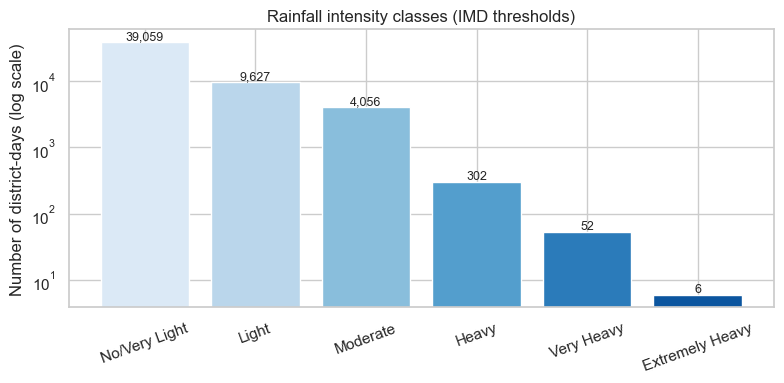

In [11]:
INTENSITY_LABELS = ["No/Very Light", "Light", "Moderate", "Heavy", "Very Heavy", "Extremely Heavy"]
INTENSITY_BINS = [-np.inf, 2.45, 15.55, 64.45, 115.55, 204.45, np.inf]   # edges between 0.1 mm steps

df["rain_intensity"] = pd.cut(df["daily_actual"], bins=INTENSITY_BINS, labels=INTENSITY_LABELS)
df["rain_intensity_code"] = df["rain_intensity"].cat.codes          # 0..5, ordered by severity

dist = df["rain_intensity"].value_counts().reindex(INTENSITY_LABELS)
display(pd.DataFrame({"rows": dist, "percent": (dist / len(df) * 100).round(3)}))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dist.index, dist.values, color=sns.color_palette("Blues", 6))
ax.set_yscale("log")
ax.set_ylabel("Number of district-days (log scale)")
ax.set_title("Rainfall intensity classes (IMD thresholds)")
for i, v in enumerate(dist.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "m1_intensity_distribution.png"), dpi=150)
plt.show()

**Interpretation (class imbalance).** The classes are extremely imbalanced: about 73.6% of records are *No/Very Light*, while *Heavy* has 302 records, *Very Heavy* 52 and *Extremely Heavy* only 6 out of 53,102. Accuracy alone would look excellent for a model that always predicts "No/Very Light". In Module 6 we will therefore use class weights, report recall for heavy classes, and decide how to treat the rarest class (for example merging Very Heavy and Extremely Heavy) — that decision is made and documented there, not here.

## Step 12 — Outliers and the leakage warning
### 12a. Outliers
Rainfall is **zero-inflated and right-skewed** (most days are 0 mm). The textbook IQR rule (Q3 + 1.5×IQR) breaks down here, so we show why and use a domain-based rule instead.

Q1=0.0  Q3=2.9  IQR=2.9  -> IQR upper fence = 7.25 mm
Rows above the IQR fence: 15.8% of all records (far too many to be 'errors')

Percentiles of daily_actual (mm):


,mm
count,53102.00
mean,4.28
std,11.44
min,0.00
50%,0.00
90%,13.10
95%,23.40
99%,55.20
99.9%,117.41
max,231.90


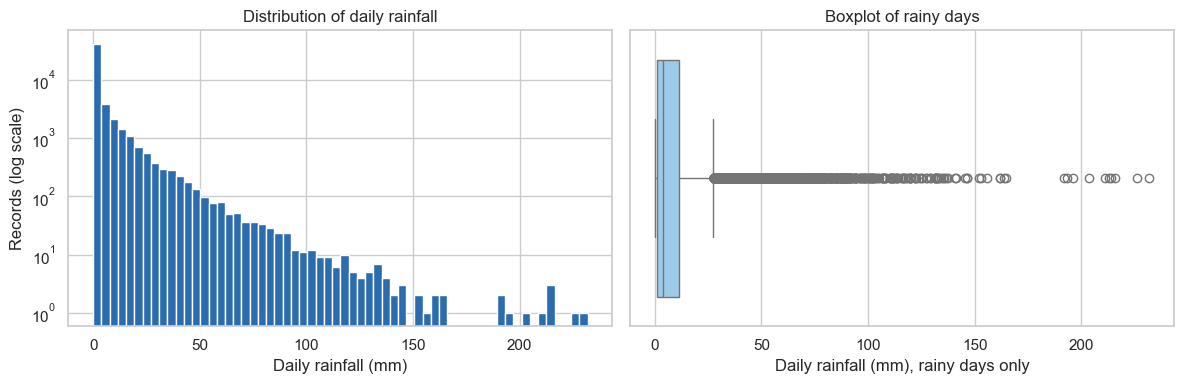


10 most extreme district-days:


,state,district,date,daily_actual,daily_normal,rain_intensity
34493,ODISHA,NABARANGAPUR,2026-09-25,231.9,4.2,Extremely Heavy
1895,ANDHRA PRADESH,VISHAKHAPATNAM,2026-10-28,226.0,5.3,Extremely Heavy
1968,ANDHRA PRADESH,VIZIANAGARAM,2026-10-28,215.7,2.3,Extremely Heavy
289,ANDHRA PRADESH,ANAKAPALLI,2026-10-28,213.8,4.1,Extremely Heavy
34016,ODISHA,KANDHAMAL,2026-10-29,213.1,1.0,Extremely Heavy
1861,ANDHRA PRADESH,VISHAKHAPATNAM,2026-09-24,211.0,5.7,Extremely Heavy
34274,ODISHA,KORAPUT,2026-09-25,203.7,4.7,Very Heavy
33651,ODISHA,GANJAM,2026-10-29,196.0,1.7,Very Heavy
45986,UTTAR PRADESH,BAHRAICH,2026-09-26,193.1,3.9,Very Heavy
8797,CHHATTISGARH,BASTAR,2026-09-25,191.7,3.8,Very Heavy


In [12]:
q1, q3 = df["daily_actual"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
flag_share = (df["daily_actual"] > upper).mean() * 100
print(f"Q1={q1:.1f}  Q3={q3:.1f}  IQR={iqr:.1f}  -> IQR upper fence = {upper:.2f} mm")
print(f"Rows above the IQR fence: {flag_share:.1f}% of all records (far too many to be 'errors')")

print("\nPercentiles of daily_actual (mm):")
display(df["daily_actual"].describe(percentiles=[.5, .9, .95, .99, .999]).round(2).to_frame("mm"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["daily_actual"], bins=60, color="#2b6cb0")
axes[0].set_yscale("log")
axes[0].set_xlabel("Daily rainfall (mm)"); axes[0].set_ylabel("Records (log scale)")
axes[0].set_title("Distribution of daily rainfall")
sns.boxplot(x=df.loc[df["daily_actual"] > 0, "daily_actual"], ax=axes[1], color="#90cdf4")
axes[1].set_xlabel("Daily rainfall (mm), rainy days only")
axes[1].set_title("Boxplot of rainy days")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "m1_rainfall_outliers.png"), dpi=150)
plt.show()

print("\n10 most extreme district-days:")
display(df.nlargest(10, "daily_actual")[["state", "district", "date", "daily_actual", "daily_normal", "rain_intensity"]])

**Decision: we keep all extreme values.** The largest readings are clustered on the same dates in neighbouring districts (for example several coastal Andhra Pradesh districts on 28 Oct, and Odisha districts on 25 Sep), which looks like genuine weather systems rather than random typing errors. Heavy rainfall is exactly what this project must learn to recognise, so deleting or capping these values would remove the signal we care about. No value is negative.

### 12b. Leakage warning — which columns we will NOT use as model inputs
We check how far the weekly and monthly windows reach relative to each row's date.

In [13]:
print("Monthly window ends exactly on the row's date :", round((df["month_end"] == df["date"]).mean() * 100, 2), "%")
print("Monthly window ends AFTER the row's date      :", round((df["month_end"] > df["date"]).mean() * 100, 2), "%")
print("Weekly window ends AFTER the row's date       :", round((df["week_end"] > df["date"]).mean() * 100, 2), "%")
print("Weekly window start on/before the row's date  :", round((df["week_start"] <= df["date"]).mean() * 100, 2), "%")
print("Cumulative window starts on                   :", df["cumulative_date"].dt.date.unique().tolist())

Monthly window ends exactly on the row's date : 99.45 %
Monthly window ends AFTER the row's date      : 0.0 %
Weekly window ends AFTER the row's date       : 0.0 %
Weekly window start on/before the row's date  : 100.0 %
Cumulative window starts on                   : [datetime.date(2026, 6, 1), datetime.date(2026, 10, 1)]


**Interpretation.** No window runs past the row's own date, but they are still risky inputs:
* The **monthly** window ends exactly on the row's date (about 99.5% of rows), so it already contains that day's rainfall.
* The **weekly** label stays fixed for several consecutive rows (see the first rows of the file, where one week label covers 13–19 Aug on rows dated 19–25 Aug), so it is unclear which days the weekly numbers cover on a given row.
* The **cumulative** total restarts on a different date partway through the file, and its values are not even monotonic in the first rows (431.7 → 432.3 → 431.7), which suggests revisions.
* The **category** and **departure %** columns are computed from the same-day rainfall.

All of these are overlapping aggregates of `daily_actual`, so they add little new information and make it hard to prove that no target-period information leaks in.

**Rule for Modules 4–6:** model inputs are built only from the **district's own past `daily_actual` values** (lags, rolling mean/max) plus calendar and location features. We will not use `weekly_*`, `monthly_*`, `cumulative_*`, any `*_departure_pct` or any `*_category` column as a feature. This keeps the feature set simple, auditable and leakage-free.

## Step 13 — Encode categorical variables
* **State and district** → integer IDs with `LabelEncoder` (saved with Joblib, so the Flask app in Module 8 uses the *same* mapping as training).
* **IMD category columns** → an ordered code (NR=0 … LE=5; `ND` stays missing). These codes are for **EDA only** (e.g. the correlation heatmap in Module 2), never for model input.

In [14]:
le_state, le_district = LabelEncoder(), LabelEncoder()
df["state_enc"] = le_state.fit_transform(df["state"])
df["district_enc"] = le_district.fit_transform(df["district"])

CAT_ORDER = {"NR": 0, "LD": 1, "D": 2, "N": 3, "E": 4, "LE": 5}   # ND -> NaN
for lvl in ["daily", "weekly", "cumulative", "monthly"]:
    df[f"{lvl}_category_code"] = df[f"{lvl}_category"].map(CAT_ORDER)

joblib.dump({"state": le_state, "district": le_district},
            os.path.join(PROJECT_ROOT, "models", "label_encoders.joblib"))
with open(os.path.join(PROJECT_ROOT, "models", "intensity_thresholds.json"), "w") as f:
    json.dump({"labels": INTENSITY_LABELS,
               "bins": [None if np.isinf(b) else b for b in INTENSITY_BINS]}, f, indent=2)

print("States encoded   :", len(le_state.classes_))
print("Districts encoded:", len(le_district.classes_))
display(df[["state", "state_enc", "district", "district_enc"]].drop_duplicates().head())

States encoded   : 37
Districts encoded: 728


,state,state_enc,district,district_enc
0,ANDAMAN & NICOBAR,0,NICOBAR,470
73,ANDAMAN & NICOBAR,0,NORTH & MIDDLE ANDAMAN,476
146,ANDAMAN & NICOBAR,0,SOUTH ANDAMAN,623
219,ANDHRA PRADESH,1,ANAKAPALLI,21
292,ANDHRA PRADESH,1,ANANTAPURAMU,23


## Step 14 — Calendar features
We add year, month, day, day of week (Monday = 0) and day of year.

**Honest note for the viva:** the data covers only 19 Aug – 30 Oct 2026, so `year` is constant (zero information) and `month` takes only three values (8, 9, 10). We create them because the assignment lists them, but in Module 5 we will check their usefulness and drop `year`. Lag and rolling rainfall features (previous day, 3-day, 7-day, rolling mean/max) are built **per district** in Module 4.

In [15]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["day_of_week"] = df["date"].dt.dayofweek
df["day_of_year"] = df["date"].dt.dayofyear

print("Distinct years :", df["year"].unique().tolist())
print("Distinct months:", sorted(df["month"].unique().tolist()))
display(df[["date", "year", "month", "day", "day_of_week", "day_of_year"]].head())

Distinct years : [2026]
Distinct months: [8, 9, 10]


,date,year,month,day,day_of_week,day_of_year
0,2026-08-19,2026,8,19,2,231
1,2026-08-20,2026,8,20,3,232
2,2026-08-21,2026,8,21,4,233
3,2026-08-22,2026,8,22,5,234
4,2026-08-23,2026,8,23,6,235


## Step 15 — Final checks and save the cleaned dataset

In [16]:
# drop the raw text windows (we keep the parsed start/end dates)
df = df.drop(columns=["week_date", "monthly_date"])

# ---- integrity checks (the cell fails loudly if something is wrong) ----
assert not df.duplicated(subset=["state", "district", "date"]).any()
assert df[["state", "district", "date", "daily_actual", "daily_normal"]].notna().all().all()
assert (df["daily_actual"] >= 0).all()
assert df["state"].nunique() == 37 and df["district"].nunique() == 728
assert df.equals(df.sort_values(["state", "district", "date"]).reset_index(drop=True))

OUT_PATH = os.path.join(PROJECT_ROOT, "data", "processed", "rainfall_cleaned.csv")
df.to_csv(OUT_PATH, index=False)

print("Saved:", OUT_PATH)
print("Final shape:", df.shape)
print("States:", df["state"].nunique(), "| Districts:", df["district"].nunique(),
      "| Dates:", df["date"].min().date(), "->", df["date"].max().date())
print("\nFinal columns:")
print(list(df.columns))
display(df.head())

Saved: C:\Users\ahmed\Downloads\data\processed\rainfall_cleaned.csv
Final shape: (53102, 38)
States: 37 | Districts: 728 | Dates: 2026-08-19 -> 2026-10-30

Final columns:
['state', 'district', 'date', 'daily_actual', 'daily_normal', 'daily_category', 'weekly_actual', 'weekly_normal', 'weekly_category', 'cumulative_date', 'cumulative_actual', 'cumulative_normal', 'cumulative_category', 'monthly_actual', 'monthly_normal', 'monthly_category', 'week_start', 'week_end', 'month_start', 'month_end', 'daily_departure_pct', 'weekly_departure_pct', 'cumulative_departure_pct', 'monthly_departure_pct', 'days_since_prev_record', 'rain_intensity', 'rain_intensity_code', 'state_enc', 'district_enc', 'daily_category_code', 'weekly_category_code', 'cumulative_category_code', 'monthly_category_code', 'year', 'month', 'day', 'day_of_week', 'day_of_year']


,state,district,date,daily_actual,daily_normal,daily_category,weekly_actual,weekly_normal,weekly_category,cumulative_date,cumulative_actual,cumulative_normal,cumulative_category,monthly_actual,monthly_normal,monthly_category,week_start,week_end,month_start,month_end,daily_departure_pct,weekly_departure_pct,cumulative_departure_pct,monthly_departure_pct,days_since_prev_record,rain_intensity,rain_intensity_code,state_enc,district_enc,daily_category_code,weekly_category_code,cumulative_category_code,monthly_category_code,year,month,day,day_of_week,day_of_year
0,ANDAMAN & NICOBAR,NICOBAR,2026-08-19,0.5,7.4,LD,0.5,7.4,LD,2026-06-01,431.7,686.9,D,186.1,141.5,E,2026-08-13,2026-08-19,2026-08-01,2026-08-19,-94.0,-94.0,-37.0,31.0,NaN,No/Very Light,0,0,470,1.0,1.0,2.0,4.0,2026,8,19,2,231
1,ANDAMAN & NICOBAR,NICOBAR,2026-08-20,0.5,9.4,LD,17.5,45.2,LD,2026-06-01,432.3,696.3,D,186.6,150.9,E,2026-08-13,2026-08-19,2026-08-01,2026-08-20,-94.0,-61.0,-38.0,24.0,1.0,No/Very Light,0,0,470,1.0,1.0,2.0,4.0,2026,8,20,3,232
2,ANDAMAN & NICOBAR,NICOBAR,2026-08-21,2.4,9.9,LD,17.5,45.2,LD,2026-06-01,431.7,686.9,D,189.0,160.8,N,2026-08-13,2026-08-19,2026-08-01,2026-08-21,-76.0,-61.0,-37.0,18.0,1.0,No/Very Light,0,0,470,1.0,1.0,2.0,3.0,2026,8,21,4,233
3,ANDAMAN & NICOBAR,NICOBAR,2026-08-22,9.3,7.1,E,17.5,45.2,LD,2026-06-01,444.0,713.3,D,198.3,167.9,N,2026-08-13,2026-08-19,2026-08-01,2026-08-22,31.0,-61.0,-38.0,18.0,1.0,Light,1,0,470,4.0,1.0,2.0,3.0,2026,8,22,5,234
4,ANDAMAN & NICOBAR,NICOBAR,2026-08-23,1.3,7.9,LD,1.3,7.9,LD,2026-06-01,445.3,721.2,D,199.7,175.8,N,2026-08-13,2026-08-19,2026-08-01,2026-08-23,-83.0,-83.0,-38.0,14.0,1.0,No/Very Light,0,0,470,1.0,1.0,2.0,3.0,2026,8,23,6,235
